# 01 · Data Collection & Panel Building

**Goal:** turn seven free, public data sources into one tidy panel of
*sector × time × signal*, which every later notebook reads.

| Signal family | Source | What it proxies | Granularity | Since |
|---|---|---|---|---|
| SF attention | Google Trends, SF Bay Area metro (`US-CA-807`) | consumer/market interest in SF | monthly | 2004 |
| SF attention | Hacker News (Algolia API) | builder & investor chatter | quarterly | 2007 |
| SF founders | Y Combinator directory | where founders are actually placing bets | per batch | 2005 |
| SF builders | GitHub repo search | developers shipping code | yearly | 2009 |
| Research | OpenAlex | academic/R&D activity | yearly | — |
| **SEA attention** | Google Trends: SG, ID, VN, PH, TH, MY | SEA consumer/market interest | monthly | 2004 |
| **SEA attention** | Wikipedia pageviews (id, vi, th, ms, tl) | SEA public curiosity | monthly | 2015 |
| SEA readiness | World Bank | internet, income, banking, urbanisation | yearly | 2005 |

**Two rules that matter for rigour**
1. **Shares, not counts.** HN, GitHub and the research literature all grew massively.
   Raw counts make *everything* look like a trend. Every count is divided by its
   platform's total activity in the same period.
2. **Scale-free features only (later notebooks).** Google Trends rescales each series so its
   all-time max = 100, which quietly leaks the future. So every feature used for
   prediction is a ratio or growth rate that does not change if the series is rescaled.

## 1 · Setup

In [1]:
import json, re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from radar.config import SECTORS, RAW, PROC, FIG, SF_GEO, US_GEO, SEA_GEOS, SEA_WIKIS, END_YEAR
from radar import fetch

pd.set_option("display.width", 160)
print(f"{len(SECTORS)} sectors:", pd.Series({k: v['label'] for k, v in SECTORS.items()}).value_counts().to_dict())

43 sectors: {'candidate': 18, 'noise': 12, 'boom': 7, 'ambiguous': 6}


## 2 · Fetch (cached)
Every fetcher caches to `data/raw/<source>/<sector>.json`. The slow, rate-limited
sources (Google Trends, GitHub) were run in the background with
`python -m radar.fetch <source>`. Here we just confirm the cache is complete.

In [2]:
yc_raw = fetch.fetch_yc()
wb_raw = fetch.fetch_worldbank()
den = fetch.fetch_denominators()

coverage = pd.DataFrame({src: {s: (RAW / src / f"{s}.json").exists() for s in SECTORS}
                         for src in ["gtrends", "hn", "wiki", "github", "openalex"]})
print("cache coverage (sectors with data):")
print(coverage.sum().to_string())
missing = coverage[~coverage.all(axis=1)]
missing

cache coverage (sectors with data):
gtrends     19
hn          43
wiki        43
github      43
openalex    43


,gtrends,hn,wiki,github,openalex
crypto_exchanges,False,True,True,True,True
telemedicine,False,True,True,True,True
edtech,False,True,True,True,True
insurtech,False,True,True,True,True
p2p_lending,False,True,True,True,True
b2b_saas,False,True,True,True,True
generative_ai,False,True,True,True,True
ai_agents,False,True,True,True,True
ai_coding,False,True,True,True,True
ai_datacenters,False,True,True,True,True


## 3 · Y Combinator: founder supply
Each YC company is matched to sectors with the regex in `config.py`, applied to its
tags, industry and one-liner. Matching on the long description gives too many false
positives. The signal is the **share of that year's YC companies** in the sector.
The same table, built per *YC tag*, becomes the training set for the ML model in notebook 04.

In [3]:
yc = pd.DataFrame(yc_raw)
def batch_year(b):
    m = re.search(r"(20\d\d)", str(b))
    if m: return int(m.group(1))
    m = re.match(r"[WSFX](\d\d)$", str(b))     # legacy codes e.g. 'W12'
    return 2000 + int(m.group(1)) if m else np.nan
yc["year"] = yc["batch"].map(batch_year)
yc = yc.dropna(subset=["year"]).astype({"year": int})
yc = yc[yc.year <= END_YEAR]                      # a few companies are already in 2027 batches
yc["text"] = (yc["tags"].map(" ".join) + " | " + yc["one_liner"].fillna("") + " | "
              + yc["subindustry"].fillna("") + " | " + yc["industries"].map(" ".join)).str.lower()
yc["is_sea"] = yc["regions"].map(lambda r: "Southeast Asia" in r)
yc_total = yc.groupby("year").size()
print("YC companies per year (last 10):", yc_total.tail(10).to_dict())

rows = []
for s, cfg in SECTORS.items():
    hit = yc["text"].str.contains(cfg["yc"], regex=True)
    cnt = yc[hit].groupby("year").size().reindex(yc_total.index, fill_value=0)
    sea = yc[hit & yc["is_sea"]].groupby("year").size().reindex(yc_total.index, fill_value=0)
    for y in yc_total.index:
        rows += [(s, y, "yc_share", cnt[y] / yc_total[y]), (s, y, "yc_count", cnt[y]),
                 (s, y, "yc_sea_count", sea[y])]
yc_panel = pd.DataFrame(rows, columns=["sector", "year", "signal", "value"])

# spot-check the matcher: a sample of companies matched to each labelled boom
for s in ["bnpl", "digital_banks", "ride_hailing"]:
    print(f"\n{s}:", yc[yc.text.str.contains(SECTORS[s]['yc'])].sample(5, random_state=0)[["name", "year", "one_liner"]].to_string(index=False))

YC companies per year (last 10): {2017: 241, 2018: 277, 2019: 368, 2020: 438, 2021: 726, 2022: 631, 2023: 494, 2024: 590, 2025: 620, 2026: 736}



bnpl:                     name  year                                                     one_liner
                     Joe  2022 We let customers "Buy Now Pay Later" on any store in Europe. 
                 Apurata  2019     Point of sale financing for Latin America's middle class.
          Safely Finance  2019                                  BNPL for moving and renting.
Gerald Technologies, Inc  2021     Buy Now Pay Later + Cash Advance for Household Essentials
                 CredPal  2019 CredPal is a buy now pay later company in Africa that allows…

digital_banks:     name  year                                                 one_liner
  Cardda  2022       All-in-one spend management for businesses in Latam
    Grey  2022    Banking services for remote workers and digital nomads
    Glep  2022 AI-Native Spend platform built for Real Estate businesses
 Wallbit  2023                         Neobank for global remote workers
Envelope  2023                       Budgeting app wit

In [4]:
# YC *tag* panel (training data for notebook 04's persistence classifier)
tag_rows = yc[["year", "tags", "industry"]].explode("tags").dropna()
tag_year = tag_rows.groupby(["tags", "year"]).size().unstack(fill_value=0)
tag_year = tag_year[tag_year.sum(axis=1) >= 15]                   # enough companies to be meaningful
tag_share = tag_year.div(yc_total.reindex(tag_year.columns), axis=1)
tag_industries = tag_rows.groupby("tags")["industry"].nunique()
tag_share.to_parquet(PROC / "yc_tag_share.parquet")
tag_industries.to_frame("n_industries").to_parquet(PROC / "yc_tag_industries.parquet")
print(f"{len(tag_share)} YC tags with >=15 companies saved for ML training")

167 YC tags with >=15 companies saved for ML training


## 4 · Hacker News: builder/investor attention
Quarterly counts of stories and comments that contain any sector phrase, divided by
total HN activity in that quarter.

In [5]:
hn_den = pd.Series(den["hn"])
hn_den_y = hn_den.groupby(hn_den.index.str[:4].astype(int)).sum()      # yearly HN totals
rows = []
for s in SECTORS:
    f = RAW / "hn" / f"{s}.json"
    if not f.exists(): continue
    q = pd.DataFrame(json.loads(f.read_text())).T.sum(axis=1)       # sum over phrases
    for period, v in q.items():                                      # keys are '2015Q3' or '2015'
        rows.append((s, period, int(period[:4]), v))
hn_q = pd.DataFrame(rows, columns=["sector", "period", "year", "count"])
hn_y = hn_q.groupby(["sector", "year"])["count"].sum().reset_index()
hn_y["value"] = hn_y["count"] / hn_y.year.map(hn_den_y)
hn_panel = hn_y[["sector", "year", "value"]].assign(signal="hn_share")
hn_q.to_parquet(PROC / "hn_raw_counts.parquet")
hn_wide = hn_panel.pivot(index="year", columns="sector", values="value")
hn_wide[[c for c in ["ride_hailing", "bnpl", "nft", "generative_ai"] if c in hn_wide]].tail(12)

sector,ride_hailing,bnpl,nft,generative_ai
year,,,,
2015,0.000154,0.000000e+00,4.265151e-07,0.000000e+00
2016,0.000320,1.253021e-06,1.670695e-06,4.176738e-07
2017,0.000578,4.746889e-07,4.746889e-06,4.746889e-07
2018,0.000481,1.499487e-06,8.497094e-06,2.998974e-06
2019,0.000408,1.515820e-06,6.821192e-06,2.273731e-06
2020,0.000229,5.214381e-06,1.529552e-05,1.025842e-03
2021,0.000120,4.979852e-05,4.649340e-03,7.043421e-04
2022,0.000108,7.901080e-05,3.199169e-03,2.887430e-03
2023,0.000088,7.165987e-05,9.003346e-04,2.057957e-02


## 5 · Google Trends: SF vs SEA attention (monthly)
* **SF series:** the SF Bay Area metro. Early or niche terms can be too sparse there
  (lots of zeros), and then we fall back to the US national series, which follows the SF
  curve closely but has more volume.
* **SEA composite:** the mean of the six country series. Countries with too little
  search volume (>50% zero months since 2015) are dropped for that sector.

In [6]:
def sparse(s, since="2015-01"):
    s = s[s.index >= since]
    return len(s) == 0 or (s == 0).mean() > 0.5

gt_rows, gt_meta = [], []
for s in SECTORS:
    f = RAW / "gtrends" / f"{s}.json"
    if not f.exists(): continue
    d = {g: pd.Series(v, dtype=float) for g, v in json.loads(f.read_text()).items() if v}
    if not d: continue
    sf_src = SF_GEO if SF_GEO in d and (d[SF_GEO] == 0).mean() < 0.3 else US_GEO
    sea_ok = [g for g in SEA_GEOS if g in d and not sparse(d[g])]
    series = {"gt_sf": d.get(sf_src), "gt_us": d.get(US_GEO)}
    series.update({f"gt_{g}": d[g] for g in SEA_GEOS if g in d})
    if sea_ok:
        series["gt_sea"] = pd.concat([d[g] for g in sea_ok], axis=1).mean(axis=1)
    for sig, ser in series.items():
        if ser is None: continue
        gt_rows += [(s, pd.Timestamp(m), sig, v) for m, v in ser.items()]
    gt_meta.append(dict(sector=s, sf_source=sf_src, sea_countries=",".join(sea_ok), n_sea=len(sea_ok)))
gt_m = pd.DataFrame(gt_rows, columns=["sector", "date", "signal", "value"])
gt_meta = pd.DataFrame(gt_meta).set_index("sector").reindex(list(SECTORS))
gt_meta

,sf_source,sea_countries,n_sea
sector,,,
ride_hailing,US-CA-807,"SG,ID,VN,PH,TH,MY",6.0
food_delivery,US-CA-807,"SG,ID,VN,PH,TH,MY",6.0
digital_payments,US-CA-807,"SG,ID,VN,PH,MY",5.0
bnpl,US-CA-807,"SG,ID,VN,PH,MY",5.0
digital_banks,US,"SG,ID,VN,PH,MY",5.0
retail_investing,US,"SG,ID,PH,MY",4.0
video_streaming,US-CA-807,"SG,ID,VN,PH,TH,MY",6.0
daily_deals,US-CA-807,SG,1.0
coworking,US,"SG,ID,VN,PH,TH,MY",6.0


## 6 · Wikipedia: English vs SEA-language curiosity (monthly, from Jul 2015)

In [7]:
wd = {lang: pd.Series(v, dtype=float) for lang, v in den["wiki"].items()}
wiki_rows = []
for s in SECTORS:
    f = RAW / "wiki" / f"{s}.json"
    if not f.exists(): continue
    d = {lang: pd.Series(v, dtype=float) for lang, v in json.loads(f.read_text()).items()}
    if "en" in d:
        sh = (d["en"] / wd["en"]).dropna()
        wiki_rows += [(s, pd.Timestamp(m), "wiki_en_share", v) for m, v in sh.items()]
    sea = [lang for lang in SEA_WIKIS if lang in d]
    if sea:
        num = pd.concat([d[l] for l in sea], axis=1).sum(axis=1, min_count=1)
        tot = pd.concat([wd[l] for l in sea], axis=1).sum(axis=1)
        sh = (num / tot.reindex(num.index)).dropna()
        wiki_rows += [(s, pd.Timestamp(m), "wiki_sea_share", v) for m, v in sh.items()]
wiki_m = pd.DataFrame(wiki_rows, columns=["sector", "date", "signal", "value"])
print(wiki_m.groupby("signal").sector.nunique())

signal
wiki_en_share     43
wiki_sea_share    31
Name: sector, dtype: int64


## 7 · GitHub (builders) and OpenAlex (research)
Both are yearly. GitHub's search API caps very large counts, so its denominator is
the number of repos created on one fixed sample day (15 June) each year. It is a
proportional index of platform growth, and the analysis only needs the shape.
2026 runs January to September only, so GitHub 2026 counts are annualised (×12/9).

In [8]:
rows = []
gh_den = pd.Series(den["github"], dtype=float)
oa_den = pd.Series(den["openalex"], dtype=float)
for s in SECTORS:
    f = RAW / "github" / f"{s}.json"
    if f.exists():
        for y, v in json.loads(f.read_text()).items():
            v = v * 12 / 9 if int(y) == END_YEAR else v
            rows.append((s, int(y), "gh_share", v / gh_den.get(y, np.nan)))
    f = RAW / "openalex" / f"{s}.json"
    if f.exists():
        for y, v in json.loads(f.read_text()).items():
            if 2004 <= int(y) <= END_YEAR:
                rows.append((s, int(y), "oa_share", v / oa_den.get(y, np.nan)))
gho_panel = pd.DataFrame(rows, columns=["sector", "year", "signal", "value"])

## 8 · World Bank: SEA readiness indicators

In [9]:
wb = pd.DataFrame(wb_raw)
wb_latest = (wb.sort_values("year").groupby(["country", "indicator"]).last()["value"]
               .unstack().round(1))
wb.to_parquet(PROC / "worldbank.parquet")
wb_latest

indicator,account_ownership_pct,electricity_access_pct,gdp_pc_ppp,internet_users_pct,population,urban_pct
country,,,,,,
IDN,56.3,99.9,15091.0,72.8,285721236.0,59.4
MYS,88.7,100.0,35461.4,98.0,35977838.0,77.4
PHL,50.2,94.8,10747.5,67.3,116786962.0,55.8
SGP,98.0,100.0,139592.6,94.4,6111175.0,100.0
THA,91.8,100.0,22431.8,90.9,71619863.0,62.8
USA,97.0,100.0,76931.3,94.7,341784857.0,80.2
VNM,70.6,100.0,15457.3,84.2,101598527.0,38.8


## 9 · Assemble the panels

In [10]:
# Fallback: where Google Trends is missing (rate limits), use Wikipedia as the attention series:
# English-Wikipedia share stands in for SF attention, SEA-language share for SEA attention.
# Only covers Jul 2015 onward, so it serves the recent candidates, not the 2010-era backtest cases.
fallback = []
for s in SECTORS:
    have = set(gt_m.loc[gt_m.sector == s, "signal"])
    for gt_sig, wk_sig in [("gt_sf", "wiki_en_share"), ("gt_sea", "wiki_sea_share")]:
        if gt_sig not in have:
            w = wiki_m[(wiki_m.sector == s) & (wiki_m.signal == wk_sig)]
            if len(w) >= 36:
                fallback.append(w.assign(signal=gt_sig))
                gt_meta.loc[s, f"{gt_sig}_source"] = f"wikipedia ({wk_sig})"
for s in gt_meta.index:
    for gt_sig in ("gt_sf", "gt_sea"):
        if pd.isna(gt_meta.loc[s].get(f"{gt_sig}_source", np.nan)) and s in set(gt_m.sector):
            gt_meta.loc[s, f"{gt_sig}_source"] = "google trends"
print("sectors using the Wikipedia fallback:", sorted({d.sector.iloc[0] for d in fallback}))
monthly = pd.concat([gt_m, wiki_m] + fallback, ignore_index=True)
monthly_yearly = (monthly.assign(year=monthly.date.dt.year)
                  .groupby(["sector", "year", "signal"])["value"].mean().reset_index())
yearly = pd.concat([yc_panel, hn_panel, gho_panel, monthly_yearly], ignore_index=True)
yearly = yearly[(yearly.year >= 2004) & (yearly.year <= END_YEAR)]

monthly.to_parquet(PROC / "panel_monthly.parquet")
yearly.to_parquet(PROC / "panel_yearly.parquet")
gt_meta.to_parquet(PROC / "gt_meta.parquet")
sectors_df = pd.DataFrame(SECTORS).T[["label", "sea_boom_year", "hype_peak", "why"]]
sectors_df.to_parquet(PROC / "sectors.parquet")
print("monthly:", monthly.shape, "| yearly:", yearly.shape)
yearly.pivot_table(index="sector", columns="signal", values="value", aggfunc="count").fillna(0).astype(int).head(10)

sectors using the Wikipedia fallback: ['agritech', 'ai_datacenters', 'ai_healthcare', 'autonomous_vehicles', 'b2b_saas', 'carbon_markets', 'creator_economy', 'crypto_exchanges', 'cybersecurity', 'drone_delivery', 'edtech', 'electric_two_wheelers', 'embedded_finance', 'generative_ai', 'humanoid_robots', 'insurtech', 'p2p_lending', 'prediction_markets', 'smb_vertical_saas', 'social_commerce', 'stablecoins', 'telemedicine']
monthly: (55845, 4) | yearly: (10011, 4)


signal,gh_share,gt_ID,gt_MY,gt_PH,gt_SG,gt_TH,gt_VN,gt_sea,gt_sf,gt_us,hn_share,oa_share,wiki_en_share,wiki_sea_share,yc_count,yc_sea_count,yc_share
sector,,,,,,,,,,,,,,,,,
agritech,18,0,0,0,0,0,0,0,12,0,20,23,12,0,22,22,22
ai_agents,18,0,0,0,0,0,0,0,0,0,20,6,4,1,22,22,22
ai_coding,18,0,0,0,0,0,0,0,0,0,20,23,2,2,22,22,22
ai_datacenters,18,0,0,0,0,0,0,12,12,0,20,23,12,12,22,22,22
ai_healthcare,18,0,0,0,0,0,0,0,11,0,20,12,11,2,22,22,22
autonomous_vehicles,18,0,0,0,0,0,0,10,12,0,20,23,12,10,22,22,22
b2b_saas,18,0,0,0,0,0,0,12,12,0,20,23,12,12,22,22,22
battery_storage,18,0,0,0,0,0,0,0,0,0,20,23,3,0,22,22,22
bnpl,18,23,23,23,23,23,23,23,23,23,20,21,6,5,22,22,22


## 10 · Data-quality check
A signal family is **usable** for a sector when it has enough non-zero history. Sparse
cells are not filled in: later notebooks skip them and record that the
family was missing.

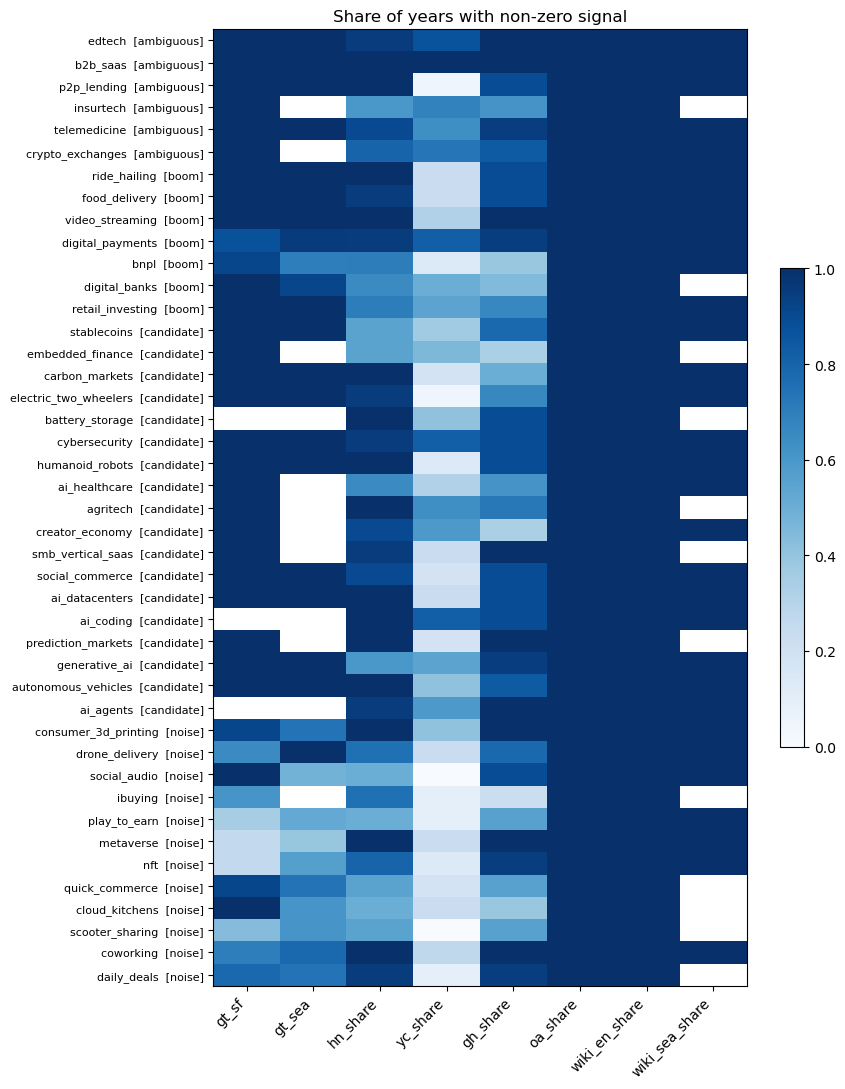

In [11]:
key = ["gt_sf", "gt_sea", "hn_share", "yc_share", "gh_share", "oa_share", "wiki_en_share", "wiki_sea_share"]
nz = (yearly[yearly.signal.isin(key)].assign(nz=lambda d: d.value > 0)
      .pivot_table(index="sector", columns="signal", values="nz", aggfunc="mean")[key])
order = sectors_df.sort_values("label").index
fig, ax = plt.subplots(figsize=(9, 11))
im = ax.imshow(nz.loc[order].values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(key)), key, rotation=45, ha="right")
ax.set_yticks(range(len(order)), [f"{s}  [{sectors_df.label[s]}]" for s in order], fontsize=8)
ax.set_title("Share of years with non-zero signal")
plt.colorbar(im, ax=ax, shrink=0.5)
plt.tight_layout(); plt.savefig(FIG / "01_coverage.png", dpi=150); plt.show()